## PMLB Benchmark

In [1]:
import torch

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"CUDA device count: {torch.cuda.device_count()}")
try:
    print(f"Current device: {torch.cuda.current_device()}")
    print(f"Device name: {torch.cuda.get_device_name(0)}")
    # Try to actually use CUDA
    x = torch.tensor([1.0]).cuda()
    print("CUDA initialization successful!")
except Exception as e:
    print(f"CUDA error: {e}")

CUDA available: True
CUDA device count: 1
Current device: 0
Device name: NVIDIA GeForce RTX 5080
CUDA initialization successful!


In [73]:
from pmlb import regression_dataset_names, fetch_data
import itertools

import sys
import os
import glob
import shap

# Get the absolute path to the parent directory
project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))

# Add hybrid_lasso to sys.path
sys.path.append(project_root)

# Now, import should work
from hybrid_lasso.model_ar_reg import AdaptiveRidgeRegression

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LassoCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# plot the results
import matplotlib.pyplot as plt

from lassonet import LassoNetRegressor
import seaborn as sns
import torch

### utils functions

In [29]:
def save_dataset(X, y, filename, test_ratio=0.5, val_ratio=0.5):
    n_features = X.shape[1]
    feature_names = [f"feature_{i}" for i in range(n_features)]
    X_df = pd.DataFrame(X, columns=feature_names)
    X_df["target"] = y

    # split into train and test
    train_df, test_df = train_test_split(X_df, test_size=test_ratio, random_state=42)
    val_df, test_df = train_test_split(test_df, test_size=val_ratio, random_state=42)

    print(train_df.shape, val_df.shape, test_df.shape)

    if not os.path.exists(f"../data/pmlb/{filename}"):
        os.makedirs(f"../data/pmlb/{filename}", exist_ok=True)

    train_df.to_csv(f"../data/pmlb/{filename}/train.csv", index=False)
    val_df.to_csv(f"../data/pmlb/{filename}/val.csv", index=False)
    test_df.to_csv(f"../data/pmlb/{filename}/test.csv", index=False)

    return train_df, val_df, test_df

In [88]:
def train_lassonet(train_df, val_df, test_df, hidden_dims=(64, 128)):
    X_train = train_df.drop("target", axis=1).values
    y_train = train_df["target"].values
    X_val = val_df.drop("target", axis=1).values
    y_val = val_df["target"].values
    X_test = test_df.drop("target", axis=1).values
    y_test = test_df["target"].values

    model = LassoNetRegressor(
        hidden_dims=hidden_dims,
        verbose=True,
        patience=(100, 5),
        random_state=42,
        torch_seed=42,
    )

    path = model.path(
        X_train,
        y_train,
        X_val=X_val,
        y_val=y_val,
        return_state_dicts=True,
    )

    best_record = min(path, key=lambda rec: rec.val_loss)

    lambda_, train_mse, val_mse, selected = (
        best_record.lambda_,
        best_record.loss,
        best_record.val_loss,
        best_record.selected,
    )

    print(
        f"Best λ: {lambda_:.3f}, Train MSE: {train_mse:.3f}, Val MSE: {val_mse:.3f}, Selected: {selected.sum()}"
    )

    # test
    model.load(best_record.state_dict)
    y_test_pred = model.predict(X_test)
    test_mse = mean_squared_error(y_test, y_test_pred)

    return test_mse


def train_lasso_cv(train_df, test_df, cv=5, alphas=None):
    X_train = train_df.drop(columns="target")
    y_train = train_df["target"]
    X_test = test_df.drop(columns="target")
    y_test = test_df["target"]

    # Create pipeline with scaling and LassoCV
    lasso_pipeline = make_pipeline(
        StandardScaler(),
        LassoCV(alphas=alphas, cv=cv, max_iter=20000, random_state=42, fit_intercept=False),
    )

    # Fit model
    lasso_pipeline.fit(X_train, y_train)

    # Predict and evaluate
    y_pred = lasso_pipeline.predict(X_test)
    test_mse = mean_squared_error(y_test, y_pred)

    # Extract best alpha
    best_model = lasso_pipeline.named_steps["lassocv"]
    best_alpha = best_model.alpha_

    return best_model, best_alpha, test_mse

In [66]:
# Function to identify feature types
def identify_feature_types(X):
    """
    Identify binary, categorical, and continuous features
    """
    binary_features = []
    categorical_features = []
    continuous_features = []

    for col in X.columns:
        unique_vals = X[col].nunique()

        # Binary features (only 2 unique values)
        if unique_vals == 2:
            binary_features.append(col)
        # Categorical features (3-10 unique values and all integers)
        elif (
            unique_vals <= 10
            and X[col].dtype in ["int64", "int32"]
            and (X[col] == X[col].astype(int)).all()
        ):
            categorical_features.append(col)
        # Continuous features
        else:
            continuous_features.append(col)

    return binary_features, categorical_features, continuous_features

In [70]:
def get_simplenn_mse(dataset, test_df):
    expr_name = f"predictions_nimo_pmlb_nn_{dataset}.pt"
    nn_pred = torch.load(f"../ckpts/{expr_name}")
    nn_preds = []
    for li in nn_pred:
        for i in li:
            nn_preds.append(i)
    pred_nn = np.array(nn_preds)

    mse_loss_nn = mean_squared_error(test_df["target"], pred_nn)
    return mse_loss_nn


def get_nimo_mse(dataset):
    expr_name = f"predictions_nimo_pmlb_{dataset}.pt"
    nimo_pred = torch.load(f"../ckpts/{expr_name}")
    nimo_preds = []
    for li in nimo_pred:
        for i in li:
            nimo_preds.append(i)
    pred_nimo = np.array(nimo_preds)

    # Load test set
    test_df = pd.read_csv(f"../data/pmlb/{dataset}/test.csv")
    mse_loss_nimo = mean_squared_error(test_df["target"], pred_nimo)
    return mse_loss_nimo

In [77]:
def plot_nimo(ckpt, train_df, figsize1=(4, 3), figsize2=(1, 6), hidden_dim=None, name=None):
    if hidden_dim is None:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt)
    else:
        model = AdaptiveRidgeRegression.load_from_checkpoint(ckpt, hidden_dim=hidden_dim)

    beta = model.beta.detach().cpu().numpy()
    beta_0 = model.beta_0.detach().cpu().numpy()

    print(beta, beta_0)

    plt.figure(figsize=figsize1)
    plt.gca().set_axisbelow(True)

    feature_names = train_df.columns[:-1].tolist() + ["Intercept"]
    coefficients = np.append(beta, beta_0)
    plt.barh(feature_names, coefficients)
    plt.xlabel("Coefficient Value")
    plt.ylabel("Feature Name")
    plt.title("Feature Coefficients of NIMO")
    if name is not None:
        plt.savefig(f"../{name}_nimo_coeff.pdf", dpi=300)
    plt.show()

    # Plot FC layer weights
    first_fc_layer = model.fc1.weight.detach().cpu().numpy()
    first_fc_layer = first_fc_layer[:, : len(train_df.columns) - 1]

    plt.figure(figsize=figsize2)
    plt.imshow(first_fc_layer, aspect="auto", cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Weight Magnitude")
    plt.title("First FC Layer Weights")
    if first_fc_layer.shape[1] <= 5:
        plt.xticks(ticks=[0, first_fc_layer.shape[1] - 1], labels=[1, first_fc_layer.shape[1]])
    else:
        plt.xticks(
            ticks=np.arange(0, first_fc_layer.shape[1], 5),
            labels=np.arange(1, first_fc_layer.shape[1] + 1, 5),
        )
    plt.xlabel("Input Features")
    plt.ylabel("Neurons")
    if name is not None:
        plt.savefig(f"../{name}_fc_weights.pdf", dpi=300)
    plt.show()

    return coefficients

### Filter regression datasets

In [ ]:
filtered_datasets = []

for regression_dataset in regression_dataset_names:
    try:
        X, y = fetch_data(regression_dataset, return_X_y=True)
        if not (X.shape[0] > 1000 and X.shape[0] < 16384):
            continue

        print(regression_dataset)
        filtered_datasets.append(regression_dataset)
        print(f"number of samples: {X.shape[0]}, number of features: {X.shape[1]}")
        print("")

    except Exception as e:
        pass

In [75]:
filtered_datasets = [
    "197_cpu_act",
    "201_pol",
    "225_puma8NH",
    "227_cpu_small",
    "294_satellite_image",
    "4544_GeographicalOriginalofMusic",
    "503_wind",
    "529_pollen",
    "562_cpu_small",
    "573_cpu_act",
]

### Feature processing

In [36]:
# go through each dataset and count feature nums
feat_nums = []
for ds_name in filtered_datasets:
    try:
        X, y = fetch_data(ds_name, return_X_y=True)
        n_features = X.shape[1]
        print(f"Dataset: {ds_name}, Number of features: {n_features}")
        feat_nums.append(n_features)
    except Exception as e:
        print(f"  ✗ Failed to fetch data for {ds_name}: {e}")

Dataset: 197_cpu_act, Number of features: 21
Dataset: 201_pol, Number of features: 48
Dataset: 225_puma8NH, Number of features: 8
Dataset: 227_cpu_small, Number of features: 12
Dataset: 294_satellite_image, Number of features: 36
Dataset: 4544_GeographicalOriginalofMusic, Number of features: 117
Dataset: 503_wind, Number of features: 14
Dataset: 529_pollen, Number of features: 4
Dataset: 562_cpu_small, Number of features: 12
Dataset: 573_cpu_act, Number of features: 21
Dataset: banana, Number of features: 2
Dataset: titanic, Number of features: 8


In [67]:
# remove banana and titanic
feat_nums = [21, 48, 8, 12, 36, 117, 14, 4, 12, 21]

### Processing and saving each dataset

In [32]:
# Process features AND targets for each dataset with proper type handling
for ds_name in filtered_datasets:
    try:
        print(f"\nProcessing features for {ds_name}...")

        # Load the split datasets
        train_df = pd.read_csv(f"../data/pmlb/{ds_name}/train.csv")
        val_df = pd.read_csv(f"../data/pmlb/{ds_name}/val.csv")
        test_df = pd.read_csv(f"../data/pmlb/{ds_name}/test.csv")

        # Separate features and target
        X_train = train_df.drop("target", axis=1)
        y_train = train_df["target"]
        X_val = val_df.drop("target", axis=1)
        y_val = val_df["target"]
        X_test = test_df.drop("target", axis=1)
        y_test = test_df["target"]

        # Identify feature types
        binary_features, categorical_features, continuous_features = identify_feature_types(
            X_train
        )

        print(f"  Binary features ({len(binary_features)}): {binary_features[:5]}")
        print(f"  Categorical features ({len(categorical_features)}): {categorical_features[:5]}")
        print(f"  Continuous features ({len(continuous_features)}): {continuous_features[:5]}")

        # Process continuous features only (standardize)
        if continuous_features:
            feature_scaler = StandardScaler()
            X_train[continuous_features] = feature_scaler.fit_transform(
                X_train[continuous_features]
            )
            X_val[continuous_features] = feature_scaler.transform(X_val[continuous_features])
            X_test[continuous_features] = feature_scaler.transform(X_test[continuous_features])

        # Normalize targets (important for hybrid neural network + lasso models)
        target_scaler = StandardScaler()
        y_train_scaled = target_scaler.fit_transform(y_train.values.reshape(-1, 1)).flatten()
        y_val_scaled = target_scaler.transform(y_val.values.reshape(-1, 1)).flatten()
        y_test_scaled = target_scaler.transform(y_test.values.reshape(-1, 1)).flatten()

        print(f"  Target range before: [{y_train.min():.2f}, {y_train.max():.2f}]")
        print(f"  Target range after: [{y_train_scaled.min():.2f}, {y_train_scaled.max():.2f}]")

        # Create new dataframes with processed features and targets
        train_df_processed = X_train.copy()
        train_df_processed["target"] = y_train_scaled

        val_df_processed = X_val.copy()
        val_df_processed["target"] = y_val_scaled

        test_df_processed = X_test.copy()
        test_df_processed["target"] = y_test_scaled

        # Save processed datasets
        train_df_processed.to_csv(f"../data/pmlb/{ds_name}/train.csv", index=False)
        val_df_processed.to_csv(f"../data/pmlb/{ds_name}/val.csv", index=False)
        test_df_processed.to_csv(f"../data/pmlb/{ds_name}/test.csv", index=False)

        # Save the target scaler for later denormalization
        import joblib

        joblib.dump(target_scaler, f"../data/pmlb/{ds_name}/target_scaler.pkl")

        print(f"  ✓ Completed {ds_name}")

    except Exception as e:
        print(f"  ✗ Failed to process {ds_name}: {e}")


Processing features for 197_cpu_act...
  Binary features (0): []
  Categorical features (0): []
  Continuous features (21): ['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4']
  Target range before: [0.00, 99.00]
  Target range after: [-4.43, 0.81]
  ✓ Completed 197_cpu_act

Processing features for 201_pol...
  Binary features (0): []
  Categorical features (0): []
  Continuous features (48): ['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4']
  Target range before: [0.00, 100.00]
  Target range after: [-0.70, 1.68]
  ✓ Completed 201_pol

Processing features for 225_puma8NH...
  Binary features (0): []
  Categorical features (0): []
  Continuous features (8): ['feature_0', 'feature_1', 'feature_2', 'feature_3', 'feature_4']
  Target range before: [-11.54, 11.14]
  Target range after: [-2.23, 1.78]
  ✓ Completed 225_puma8NH

Processing features for 227_cpu_small...
  Binary features (0): []
  Categorical features (0): []
  Continuous features (12): ['feature

### Train LassoNet

In [35]:
# Train LassoNet on all datasets
from sklearn.metrics import mean_squared_error, r2_score
import pickle

# Store results
lassonet_results = {}

for ds_name in filtered_datasets:
    print(f"\n{'=' * 60}")
    print(f"Training LassoNet on {ds_name}")
    print(f"{'=' * 60}")

    try:
        # Load processed datasets
        train_df = pd.read_csv(f"../data/pmlb/{ds_name}/train.csv")
        val_df = pd.read_csv(f"../data/pmlb/{ds_name}/val.csv")
        test_df = pd.read_csv(f"../data/pmlb/{ds_name}/test.csv")

        # Separate features and targets
        X_train = train_df.drop("target", axis=1).values
        y_train = train_df["target"].values
        X_val = val_df.drop("target", axis=1).values
        y_val = val_df["target"].values
        X_test = test_df.drop("target", axis=1).values
        y_test = test_df["target"].values

        print(
            f"Train shape: {X_train.shape}, Val shape: {X_val.shape}, Test shape: {X_test.shape}"
        )

        mse_lassonet = train_lassonet(train_df, val_df, test_df)
        print(f"LassoNet Test MSE: {mse_lassonet:.3f}")

    except Exception as e:
        print(f"  ✗ Failed to train LassoNet on {ds_name}: {e}")
        continue


Training LassoNet on 197_cpu_act
Train shape: (4096, 21), Val shape: (2048, 21), Test shape: (2048, 21)
Best λ: 0.000, Train MSE: 0.010, Val MSE: 0.024, Selected: 21
LassoNet Test MSE: 0.024

Training LassoNet on 201_pol
Train shape: (7500, 48), Val shape: (3750, 48), Test shape: (3750, 48)
Best λ: 0.000, Train MSE: 0.002, Val MSE: 0.006, Selected: 48
LassoNet Test MSE: 0.006

Training LassoNet on 225_puma8NH
Train shape: (4096, 8), Val shape: (2048, 8), Test shape: (2048, 8)
Best λ: 11.870, Train MSE: 0.264, Val MSE: 0.339, Selected: 8
LassoNet Test MSE: 0.337

Training LassoNet on 227_cpu_small
Train shape: (4096, 12), Val shape: (2048, 12), Test shape: (2048, 12)
Best λ: 0.000, Train MSE: 0.015, Val MSE: 0.025, Selected: 12
LassoNet Test MSE: 0.026

Training LassoNet on 294_satellite_image
Train shape: (3217, 36), Val shape: (1609, 36), Test shape: (1609, 36)
Best λ: 38.947, Train MSE: 0.060, Val MSE: 0.114, Selected: 36
LassoNet Test MSE: 0.104

Training LassoNet on 4544_Geographi

In [3]:
mses_lassonet = [0.024, 0.006, 0.337, 0.026, 0.104, 0.222, 0.208, 0.215, 0.026, 0.024]

### Collect NN results for all datasets with different dropout

In [78]:
# Define dropout values
DROPOUT_VALUES = [0.5, 0.3, 0.1]


# Function to get NN MSE for a specific dropout value
def get_nn_dropout_mse(dataset, dropout):
    expr_name = f"predictions_nimo_pmlb_nn_{dataset}_dropout{dropout}.pt"
    try:
        nn_pred = torch.load(f"../ckpts/{expr_name}")
        nn_preds = []
        for li in nn_pred:
            for i in li:
                nn_preds.append(i)
        pred_nn = np.array(nn_preds)

        # Load test set
        test_df = pd.read_csv(f"../data/pmlb/{dataset}/test.csv")
        mse_loss_nn = mean_squared_error(test_df["target"], pred_nn)
        return mse_loss_nn
    except FileNotFoundError:
        print(f"File not found: {expr_name}")
        return None
    except Exception as e:
        print(f"Error processing {expr_name}: {e}")
        return None


# Collect NN results for all datasets and dropout values
nn_results = []

for dataset in filtered_datasets:
    print(f"\n{'=' * 60}")
    print(f"Processing NN for dataset: {dataset}")
    print(f"{'=' * 60}")

    for dropout in DROPOUT_VALUES:
        mse = get_nn_dropout_mse(dataset, dropout)

        result = {"dataset": dataset, "dropout": dropout, "mse": mse}
        nn_results.append(result)

        if mse is not None:
            print(f"  dropout={dropout}: MSE={mse:.4f}")
        else:
            print(f"  dropout={dropout}: FAILED")

# Create a DataFrame with all NN results
nn_results_df = pd.DataFrame(nn_results)
print("\n" + "=" * 60)
print("Summary of all NN results:")
print("=" * 60)
print(nn_results_df)


Processing NN for dataset: 197_cpu_act
  dropout=0.5: MSE=0.0180
  dropout=0.3: MSE=0.0172
  dropout=0.1: MSE=0.0178

Processing NN for dataset: 201_pol
  dropout=0.5: MSE=0.0141
  dropout=0.3: MSE=0.0094
  dropout=0.1: MSE=0.0072

Processing NN for dataset: 225_puma8NH
  dropout=0.5: MSE=0.3282
  dropout=0.3: MSE=0.3382
  dropout=0.1: MSE=0.3525

Processing NN for dataset: 227_cpu_small
  dropout=0.5: MSE=0.0246
  dropout=0.3: MSE=0.0230
  dropout=0.1: MSE=0.0233

Processing NN for dataset: 294_satellite_image
  dropout=0.5: MSE=0.1072
  dropout=0.3: MSE=0.1026
  dropout=0.1: MSE=0.0989

Processing NN for dataset: 4544_GeographicalOriginalofMusic
  dropout=0.5: MSE=0.2573
  dropout=0.3: MSE=0.2966
  dropout=0.1: MSE=0.2871

Processing NN for dataset: 503_wind
  dropout=0.5: MSE=0.2040
  dropout=0.3: MSE=0.1983
  dropout=0.1: MSE=0.2102

Processing NN for dataset: 529_pollen
  dropout=0.5: MSE=0.2125
  dropout=0.3: MSE=0.2168
  dropout=0.1: MSE=0.2205

Processing NN for dataset: 562_c

In [6]:
# Select best NN result for each dataset
print("\n" + "=" * 60)
print("Best NN configuration for each dataset:")
print("=" * 60)

best_nn_results = []

for dataset in filtered_datasets:
    dataset_results = nn_results_df[nn_results_df["dataset"] == dataset]

    # Filter out None values
    dataset_results_valid = dataset_results[dataset_results["mse"].notna()]

    if len(dataset_results_valid) > 0:
        best_idx = dataset_results_valid["mse"].idxmin()
        best_result = dataset_results_valid.loc[best_idx]
        best_nn_results.append(best_result)

        print(f"\n{dataset}:")
        print(f"  Best dropout: {best_result['dropout']}")
        print(f"  Best MSE: {best_result['mse']:.4f}")
    else:
        print(f"\n{dataset}: No valid results found")

# Create DataFrame with best NN results
best_nn_df = pd.DataFrame(best_nn_results)
print("\n" + "=" * 60)
print("Summary of best NN results:")
print("=" * 60)
print(best_nn_df[["dataset", "dropout", "mse"]])


Best NN configuration for each dataset:

197_cpu_act:
  Best dropout: 0.3
  Best MSE: 0.0172

201_pol:
  Best dropout: 0.1
  Best MSE: 0.0072

225_puma8NH:
  Best dropout: 0.5
  Best MSE: 0.3282

227_cpu_small:
  Best dropout: 0.3
  Best MSE: 0.0230

294_satellite_image:
  Best dropout: 0.1
  Best MSE: 0.0989

4544_GeographicalOriginalofMusic:
  Best dropout: 0.5
  Best MSE: 0.2573

503_wind:
  Best dropout: 0.3
  Best MSE: 0.1983

529_pollen:
  Best dropout: 0.5
  Best MSE: 0.2125

562_cpu_small:
  Best dropout: 0.3
  Best MSE: 0.0230

573_cpu_act:
  Best dropout: 0.3
  Best MSE: 0.0172

Summary of best NN results:
                             dataset  dropout       mse
1                        197_cpu_act      0.3  0.017239
5                            201_pol      0.1  0.007164
6                        225_puma8NH      0.5  0.328221
10                     227_cpu_small      0.3  0.023015
14               294_satellite_image      0.1  0.098940
15  4544_GeographicalOriginalofMusic   

In [79]:
mses_nn = np.array(best_nn_df["mse"])

In [80]:
mses_nn

array([0.01723889, 0.00716398, 0.32822079, 0.02301473, 0.09893977,
       0.25726935, 0.19833197, 0.21254444, 0.02301473, 0.01723889])

### Collect NIMO results with different hyperparameters

In [81]:
# Define parameter lists
LASSO_PENALTIES = [0.005, 0.01, 0.05, 0.1]
GROUP_PENALTIES = [0.005, 0.01, 0.05, 0.1]


# Function to get MSE for a specific parameter combination
def get_param_sweep_mse(dataset, lasso_penalty, group_penalty):
    expr_name = f"predictions_nimo_pmlb_{dataset}_lasso{lasso_penalty}_group{group_penalty}.pt"
    try:
        pred = torch.load(f"../ckpts/{expr_name}")
        preds = []
        for li in pred:
            for i in li:
                preds.append(i)
        pred_array = np.array(preds)

        # Load test set
        test_df = pd.read_csv(f"../data/pmlb/{dataset}/test.csv")
        mse_loss = mean_squared_error(test_df["target"], pred_array)
        return mse_loss
    except FileNotFoundError:
        print(f"File not found: {expr_name}")
        return None
    except Exception as e:
        print(f"Error processing {expr_name}: {e}")
        return None


# Collect results for all datasets and parameter combinations
results = []

for dataset in filtered_datasets:
    print(f"\n{'=' * 60}")
    print(f"Processing dataset: {dataset}")
    print(f"{'=' * 60}")

    for lasso_penalty, group_penalty in itertools.product(LASSO_PENALTIES, GROUP_PENALTIES):
        mse = get_param_sweep_mse(dataset, lasso_penalty, group_penalty)

        result = {
            "dataset": dataset,
            "lasso_penalty": lasso_penalty,
            "group_penalty": group_penalty,
            "mse": mse,
        }
        results.append(result)

        if mse is not None:
            print(f"  lasso={lasso_penalty}, group={group_penalty}: MSE={mse:.4f}")
        else:
            print(f"  lasso={lasso_penalty}, group={group_penalty}: FAILED")

# Create a DataFrame with all results
results_df = pd.DataFrame(results)
print("\n" + "=" * 60)
print("Summary of all results:")
print("=" * 60)
print(results_df)


Processing dataset: 197_cpu_act
  lasso=0.005, group=0.005: MSE=0.0215
  lasso=0.005, group=0.01: MSE=0.0223
  lasso=0.005, group=0.05: MSE=0.0778
  lasso=0.005, group=0.1: MSE=0.0836
  lasso=0.01, group=0.005: MSE=0.0206
  lasso=0.01, group=0.01: MSE=0.0225
  lasso=0.01, group=0.05: MSE=0.0671
  lasso=0.01, group=0.1: MSE=0.0847
  lasso=0.05, group=0.005: MSE=0.0213
  lasso=0.05, group=0.01: MSE=0.0219
  lasso=0.05, group=0.05: MSE=0.0643
  lasso=0.05, group=0.1: MSE=0.0854
  lasso=0.1, group=0.005: MSE=0.0216
  lasso=0.1, group=0.01: MSE=0.0219
  lasso=0.1, group=0.05: MSE=0.0637
  lasso=0.1, group=0.1: MSE=0.0874

Processing dataset: 201_pol
  lasso=0.005, group=0.005: MSE=0.0259
  lasso=0.005, group=0.01: MSE=0.0321
  lasso=0.005, group=0.05: MSE=0.0744
  lasso=0.005, group=0.1: MSE=0.1192
  lasso=0.01, group=0.005: MSE=0.0261
  lasso=0.01, group=0.01: MSE=0.0316
  lasso=0.01, group=0.05: MSE=0.0784
  lasso=0.01, group=0.1: MSE=0.1190
  lasso=0.05, group=0.005: MSE=0.0261
  lasso=

In [82]:
# Select best NIMO result for each dataset
print("\n" + "=" * 60)
print("Best NIMO configuration for each dataset:")
print("=" * 60)

best_nimo_results = []

for dataset in filtered_datasets:
    dataset_results = results_df[results_df["dataset"] == dataset]

    # Filter out None values
    dataset_results_valid = dataset_results[dataset_results["mse"].notna()]

    if len(dataset_results_valid) > 0:
        best_idx = dataset_results_valid["mse"].idxmin()
        best_result = dataset_results_valid.loc[best_idx]
        best_nimo_results.append(best_result)

        print(f"\n{dataset}:")
        print(f"  Best lasso_penalty: {best_result['lasso_penalty']}")
        print(f"  Best group_penalty: {best_result['group_penalty']}")
        print(f"  Best MSE: {best_result['mse']:.4f}")
    else:
        print(f"\n{dataset}: No valid results found")

# Create DataFrame with best NIMO results
best_nimo_df = pd.DataFrame(best_nimo_results)
print("\n" + "=" * 60)
print("Summary of best NIMO results:")
print("=" * 60)
print(best_nimo_df[["dataset", "lasso_penalty", "group_penalty", "mse"]])


Best NIMO configuration for each dataset:

197_cpu_act:
  Best lasso_penalty: 0.01
  Best group_penalty: 0.005
  Best MSE: 0.0206

201_pol:
  Best lasso_penalty: 0.1
  Best group_penalty: 0.005
  Best MSE: 0.0252

225_puma8NH:
  Best lasso_penalty: 0.1
  Best group_penalty: 0.005
  Best MSE: 0.4043

227_cpu_small:
  Best lasso_penalty: 0.005
  Best group_penalty: 0.005
  Best MSE: 0.0284

294_satellite_image:
  Best lasso_penalty: 0.1
  Best group_penalty: 0.005
  Best MSE: 0.1095

4544_GeographicalOriginalofMusic:
  Best lasso_penalty: 0.1
  Best group_penalty: 0.1
  Best MSE: 0.2148

503_wind:
  Best lasso_penalty: 0.005
  Best group_penalty: 0.005
  Best MSE: 0.2092

529_pollen:
  Best lasso_penalty: 0.005
  Best group_penalty: 0.005
  Best MSE: 0.2058

562_cpu_small:
  Best lasso_penalty: 0.005
  Best group_penalty: 0.005
  Best MSE: 0.0284

573_cpu_act:
  Best lasso_penalty: 0.01
  Best group_penalty: 0.005
  Best MSE: 0.0206

Summary of best NIMO results:
                       

In [86]:
mses_nimo = np.array(best_nimo_df["mse"])
mses_nimo

array([0.02059564, 0.02515725, 0.40430214, 0.02844084, 0.10953371,
       0.2147688 , 0.20919444, 0.20579662, 0.02844084, 0.02059564])

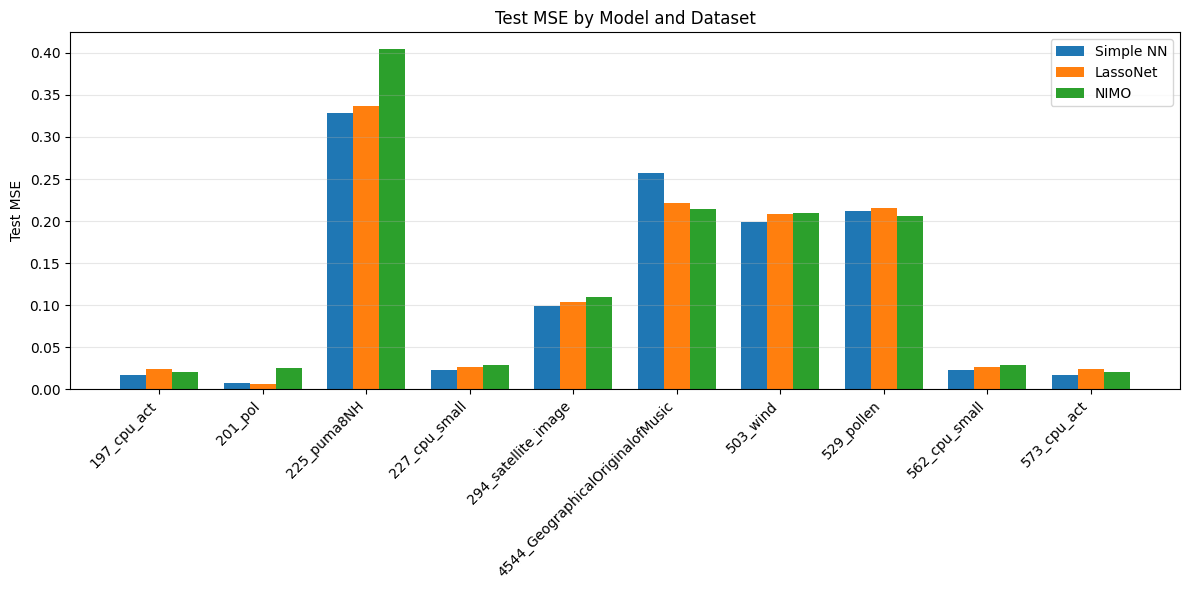

In [87]:
# plot the results
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(filtered_datasets))  # the label locations
width = 0.25  # the width of the bars
fig, ax = plt.subplots(figsize=(12, 6))
rects1 = ax.bar(x - width, mses_nn, width, label="Simple NN")
rects2 = ax.bar(x, mses_lassonet, width, label="LassoNet")
rects3 = ax.bar(x + width, mses_nimo, width, label="NIMO")

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel("Test MSE")
ax.set_title("Test MSE by Model and Dataset")
ax.set_xticks(x)
ax.set_xticklabels(filtered_datasets, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.savefig("pmlb_model_comparison.pdf", dpi=300)

# Show plot
plt.show()

### Train LassoCV

In [89]:
# Store results
lasso_results = []

for ds_name in filtered_datasets:
    print(f"\n{'=' * 60}")
    print(f"Training Lasso on {ds_name}")
    print(f"{'=' * 60}")

    train_df = pd.read_csv(f"../data/pmlb/{ds_name}/train.csv")
    val_df = pd.read_csv(f"../data/pmlb/{ds_name}/val.csv")
    test_df = pd.read_csv(f"../data/pmlb/{ds_name}/test.csv")

    # Separate features and targets
    X_train = train_df.drop("target", axis=1).values
    y_train = train_df["target"].values
    X_val = val_df.drop("target", axis=1).values
    y_val = val_df["target"].values
    X_test = test_df.drop("target", axis=1).values
    y_test = test_df["target"].values

    print(f"Train shape: {X_train.shape}, Val shape: {X_val.shape}, Test shape: {X_test.shape}")

    best_model, best_alpha, test_mse = train_lasso_cv(train_df, test_df)
    print(f"Lasso Test MSE: {test_mse:.3f}")
    lasso_results.append({"dataset": ds_name, "best_alpha": best_alpha, "test_mse": test_mse})
# from to dataframe
lasso_results_df = pd.DataFrame(lasso_results)
print("\n" + "=" * 60)
print("Lasso Results Summary:")
print("=" * 60)
print(lasso_results_df)


Training Lasso on 197_cpu_act
Train shape: (4096, 21), Val shape: (2048, 21), Test shape: (2048, 21)
Lasso Test MSE: 0.249

Training Lasso on 201_pol
Train shape: (7500, 48), Val shape: (3750, 48), Test shape: (3750, 48)
Lasso Test MSE: 0.519

Training Lasso on 225_puma8NH
Train shape: (4096, 8), Val shape: (2048, 8), Test shape: (2048, 8)
Lasso Test MSE: 0.628

Training Lasso on 227_cpu_small
Train shape: (4096, 12), Val shape: (2048, 12), Test shape: (2048, 12)
Lasso Test MSE: 0.262

Training Lasso on 294_satellite_image
Train shape: (3217, 36), Val shape: (1609, 36), Test shape: (1609, 36)
Lasso Test MSE: 0.292

Training Lasso on 4544_GeographicalOriginalofMusic
Train shape: (529, 117), Val shape: (265, 117), Test shape: (265, 117)
Lasso Test MSE: 0.224

Training Lasso on 503_wind
Train shape: (3287, 14), Val shape: (1643, 14), Test shape: (1644, 14)
Lasso Test MSE: 0.237

Training Lasso on 529_pollen
Train shape: (1924, 4), Val shape: (962, 4), Test shape: (962, 4)
Lasso Test MSE:

In [91]:
mses_lasso = np.array(lasso_results_df["test_mse"])
mses_lasso

array([0.24946721, 0.51865762, 0.62808923, 0.26208518, 0.29230795,
       0.22439151, 0.23676472, 0.20661205, 0.26208518, 0.24946721])

### Collected results before basis expansion

In [118]:
mses_lassonet = np.array([0.024, 0.006, 0.337, 0.026, 0.104, 0.222, 0.208, 0.215, 0.026, 0.024])

In [119]:
mses_nn = np.array(
    [
        0.01723889,
        0.00716398,
        0.32822079,
        0.02301473,
        0.09893977,
        0.25726935,
        0.19833197,
        0.21254444,
        0.02301473,
        0.01723889,
    ]
)

In [120]:
mses_nimo = np.array(
    [
        0.02059564,
        0.02515725,
        0.40430214,
        0.02844084,
        0.10953371,
        0.2147688,
        0.20919444,
        0.20579662,
        0.02844084,
        0.02059564,
    ]
)

In [121]:
mses_lasso = np.array(
    [
        0.24946721,
        0.51865762,
        0.62808923,
        0.26208518,
        0.29230795,
        0.22439151,
        0.23676472,
        0.20661205,
        0.26208518,
        0.24946721,
    ]
)

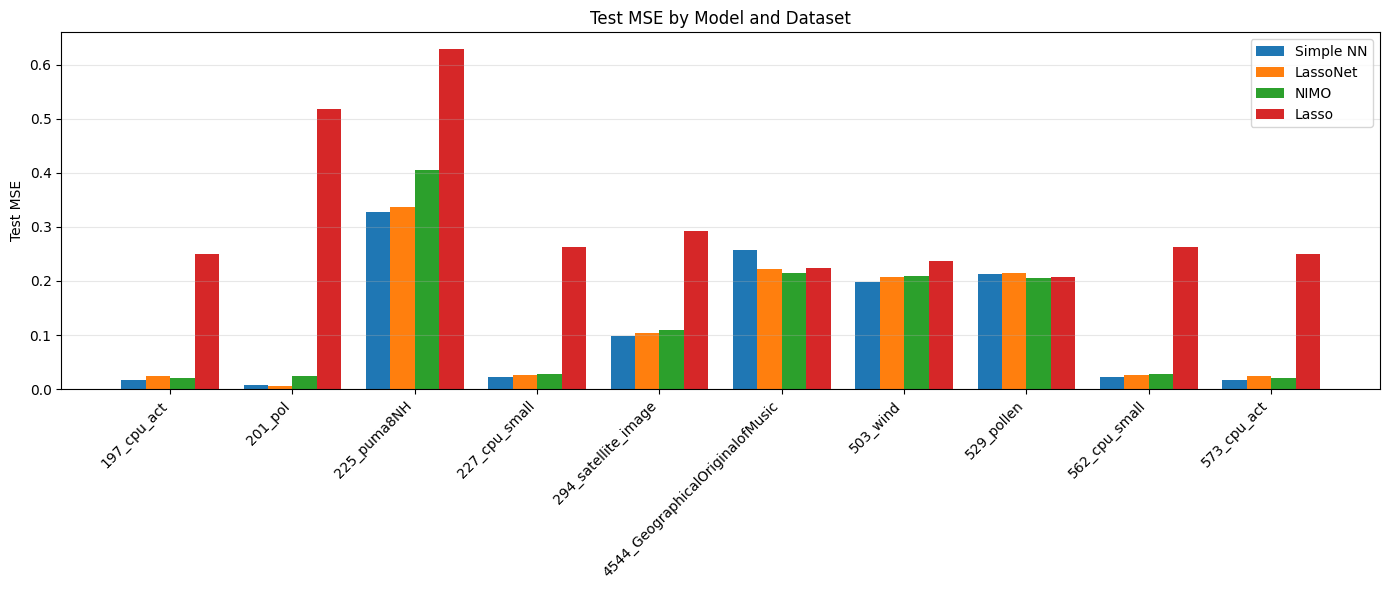

In [122]:
# plot the results
import matplotlib.pyplot as plt
import numpy as np

x = np.arange(len(filtered_datasets))  # the label locations
width = 0.2  # the width of the bars
fig, ax = plt.subplots(figsize=(14, 6))
rects1 = ax.bar(x - 1.5 * width, mses_nn, width, label="Simple NN")
rects2 = ax.bar(x - 0.5 * width, mses_lassonet, width, label="LassoNet")
rects3 = ax.bar(x + 0.5 * width, mses_nimo, width, label="NIMO")
rects4 = ax.bar(x + 1.5 * width, mses_lasso, width, label="Lasso")

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel("Test MSE")
ax.set_title("Test MSE by Model and Dataset")
ax.set_xticks(x)

xticks = filtered_datasets.copy()
ax.set_xticklabels(xticks, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
# plt.savefig('pmlb_model_comparison.png', dpi=300)

# Show plot
plt.show()

### Basis expansion to 225_puma8NH dataset

In [51]:
train_df = pd.read_csv("../data/pmlb/225_puma8NH/train.csv")
val_df = pd.read_csv("../data/pmlb/225_puma8NH/val.csv")
test_df = pd.read_csv("../data/pmlb/225_puma8NH/test.csv")


# do polynomial feature expansion and save new dataset
from sklearn.preprocessing import PolynomialFeatures

X = pd.concat(
    [
        train_df.drop("target", axis=1),
        val_df.drop("target", axis=1),
        test_df.drop("target", axis=1),
    ],
    axis=0,
).values
y = pd.concat([train_df["target"], val_df["target"], test_df["target"]], axis=0).values

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X)
train_df_poly, val_df_poly, test_df_poly = save_dataset(
    X_poly, y, "225_puma8NH_poly", test_ratio=0.5, val_ratio=0.5
)

(4096, 45) (2048, 45) (2048, 45)


### Get best hyperparameter settings for 225_puma8NH_poly dataset

In [98]:
train_df_poly = pd.read_csv("../data/pmlb/225_puma8NH_poly/train.csv")
val_df_poly = pd.read_csv("../data/pmlb/225_puma8NH_poly/val.csv")
test_df_poly = pd.read_csv("../data/pmlb/225_puma8NH_poly/test.csv")

In [117]:
# Define dropout values
DROPOUT_VALUES = [0.5, 0.3, 0.1]

puma_datasets = ["225_puma8NH_poly"]


# Function to get NN MSE for a specific dropout value
def get_nn_dropout_mse(dataset, dropout):
    expr_name = f"predictions_nimo_pmlb_nn_{dataset}_dropout{dropout}.pt"
    try:
        nn_pred = torch.load(f"../ckpts/{expr_name}")
        nn_preds = []
        for li in nn_pred:
            for i in li:
                nn_preds.append(i)
        pred_nn = np.array(nn_preds)

        # Load test set
        test_df = pd.read_csv(f"../data/pmlb/{dataset}/test.csv")
        mse_loss_nn = mean_squared_error(test_df["target"], pred_nn)
        return mse_loss_nn
    except FileNotFoundError:
        print(f"File not found: {expr_name}")
        return None
    except Exception as e:
        print(f"Error processing {expr_name}: {e}")
        return None


# Collect NN results for all datasets and dropout values
nn_puma_poly_results = []

for dataset in puma_datasets:
    print(f"\n{'=' * 60}")
    print(f"Processing NN for dataset: {dataset}")
    print(f"{'=' * 60}")

    for dropout in DROPOUT_VALUES:
        mse = get_nn_dropout_mse(dataset, dropout)

        result = {"dataset": dataset, "dropout": dropout, "mse": mse}
        nn_puma_poly_results.append(result)

        if mse is not None:
            print(f"  dropout={dropout}: MSE={mse:.4f}")
        else:
            print(f"  dropout={dropout}: FAILED")

# Create a DataFrame with all NN results
nn_puma_poly_results_df = pd.DataFrame(nn_puma_poly_results)
print("\n" + "=" * 60)
print("Summary of all NN results for 225_puma8NH_poly:")
print("=" * 60)
print(nn_puma_poly_results_df)


Processing NN for dataset: 225_puma8NH_poly
  dropout=0.5: MSE=0.3518
  dropout=0.3: MSE=0.3660
  dropout=0.1: MSE=0.3985

Summary of all NN results for 225_puma8NH_poly:
            dataset  dropout       mse
0  225_puma8NH_poly      0.5  0.351764
1  225_puma8NH_poly      0.3  0.366042
2  225_puma8NH_poly      0.1  0.398475


In [130]:
# Define parameter lists
LASSO_PENALTIES = [0.005, 0.01, 0.05, 0.1]
GROUP_PENALTIES = [0.005, 0.01, 0.05, 0.1]

puma_datasets = ["225_puma8NH_poly"]


# Function to get MSE for a specific parameter combination
def get_param_sweep_mse(dataset, lasso_penalty, group_penalty):
    expr_name = f"predictions_nimo_pmlb_{dataset}_lasso{lasso_penalty}_group{group_penalty}.pt"
    try:
        pred = torch.load(f"../ckpts/{expr_name}")
        preds = []
        for li in pred:
            for i in li:
                preds.append(i)
        pred_array = np.array(preds)

        # Load test set
        test_df = pd.read_csv(f"../data/pmlb/{dataset}/test.csv")
        mse_loss = mean_squared_error(test_df["target"], pred_array)
        return mse_loss
    except FileNotFoundError:
        print(f"File not found: {expr_name}")
        return None
    except Exception as e:
        print(f"Error processing {expr_name}: {e}")
        return None


# Collect results for all datasets and parameter combinations
nimo_puma_poly_results = []

for dataset in puma_datasets:
    print(f"\n{'=' * 60}")
    print(f"Processing dataset: {dataset}")
    print(f"{'=' * 60}")

    for lasso_penalty, group_penalty in itertools.product(LASSO_PENALTIES, GROUP_PENALTIES):
        mse = get_param_sweep_mse(dataset, lasso_penalty, group_penalty)

        result = {
            "dataset": dataset,
            "lasso_penalty": lasso_penalty,
            "group_penalty": group_penalty,
            "mse": mse,
        }
        nimo_puma_poly_results.append(result)

        if mse is not None:
            print(f"  lasso={lasso_penalty}, group={group_penalty}: MSE={mse:.4f}")
        else:
            print(f"  lasso={lasso_penalty}, group={group_penalty}: FAILED")

# Create a DataFrame with all results
results_nimo_puma_poly_df = pd.DataFrame(nimo_puma_poly_results)
print("\n" + "=" * 60)
print("Summary of all results:")
print("=" * 60)
print(results_nimo_puma_poly_df)


Processing dataset: 225_puma8NH_poly
  lasso=0.005, group=0.005: MSE=0.3395
  lasso=0.005, group=0.01: MSE=0.3380
  lasso=0.005, group=0.05: MSE=0.3466
  lasso=0.005, group=0.1: MSE=0.3490
  lasso=0.01, group=0.005: MSE=0.3388
  lasso=0.01, group=0.01: MSE=0.3395
  lasso=0.01, group=0.05: MSE=0.3462
  lasso=0.01, group=0.1: MSE=0.3485
  lasso=0.05, group=0.005: MSE=0.3381
  lasso=0.05, group=0.01: MSE=0.3367
  lasso=0.05, group=0.05: MSE=0.3449
  lasso=0.05, group=0.1: MSE=0.3471
  lasso=0.1, group=0.005: MSE=0.3402
  lasso=0.1, group=0.01: MSE=0.3365
  lasso=0.1, group=0.05: MSE=0.3451
  lasso=0.1, group=0.1: MSE=0.3471

Summary of all results:
             dataset  lasso_penalty  group_penalty       mse
0   225_puma8NH_poly          0.005          0.005  0.339507
1   225_puma8NH_poly          0.005          0.010  0.338036
2   225_puma8NH_poly          0.005          0.050  0.346635
3   225_puma8NH_poly          0.005          0.100  0.348953
4   225_puma8NH_poly          0.010     

In [131]:
results_nimo_puma_poly_df["mse"].min()

np.float64(0.336499130925329)

In [99]:
lasso_model, lasso_alpha, lasso_mse = train_lasso_cv(train_df_poly, test_df_poly)
print(f"Polynomial Lasso Test MSE: {lasso_mse:.3f} with alpha: {lasso_alpha:.5f}")

Polynomial Lasso Test MSE: 0.583 with alpha: 0.01497


In [100]:
lassonet_mse = train_lassonet(train_df_poly, val_df_poly, test_df_poly)
print(f"Polynomial LassoNet Test MSE: {lassonet_mse:.3f}")

Best λ: 60.211, Train MSE: 0.300, Val MSE: 0.306, Selected: 17
Polynomial LassoNet Test MSE: 0.335


In [123]:
mses_nn_poly = mses_nn.copy()
mses_nn_poly[2] = 0.351764

In [125]:
mses_lassonet_poly = mses_lassonet.copy()
mses_lassonet_poly[2] = 0.335

In [127]:
mses_lasso_poly = mses_lasso.copy()
mses_lasso_poly[2] = 0.583

In [132]:
mses_nimo_poly = mses_nimo.copy()
mses_nimo_poly[2] = 0.336499130925329

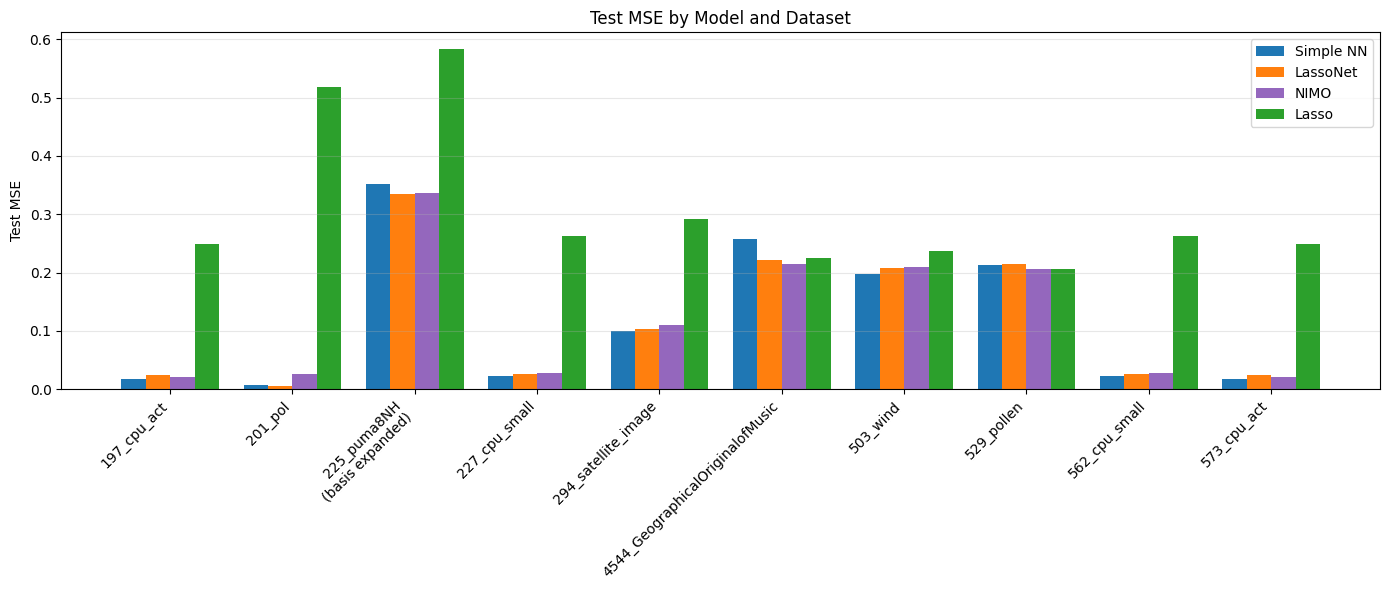

In [136]:
x = np.arange(len(filtered_datasets))  # the label locations
width = 0.2  # the width of the bars
fig, ax = plt.subplots(figsize=(14, 6))
rects1 = ax.bar(x - 1.5 * width, mses_nn_poly, width, label="Simple NN", color="tab:blue")
rects2 = ax.bar(x - 0.5 * width, mses_lassonet_poly, width, label="LassoNet", color="tab:orange")
rects3 = ax.bar(x + 0.5 * width, mses_nimo_poly, width, label="NIMO", color="tab:purple")
rects4 = ax.bar(x + 1.5 * width, mses_lasso_poly, width, label="Lasso", color="tab:green")

# Add some text for labels, title and custom x-axis tick labels, etc.
ax.set_ylabel("Test MSE")
ax.set_title("Test MSE by Model and Dataset")
ax.set_xticks(x)

xticks = filtered_datasets.copy()
xticks[2] = "225_puma8NH\n(basis expanded)"
ax.set_xticklabels(xticks, rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.savefig("../pmlb_model_comparison.pdf", dpi=300)

# Show plot
plt.show()